In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp

# Conditions for Blasius
INITIAL_f = 0.0
INITIAL_df = 0.0
FINAL_df = 1.0
ETA_0 = 0.0
ETA_MAX = 10.0
GUESS_ddf = 0.0
GUESS2_ddf = 5.0

# Constants
CONSTANT_K = np.sqrt(2)
CONSTANT_C = np.sqrt(2)

# Step size
STEP_SIZE = 0.1/CONSTANT_C
ETA_ARRAY = np.arange(ETA_0, ETA_MAX, float(STEP_SIZE))

# Blasius ODE initial condition
def blasius_rhs(eta, blasius):
    '''Input is the scaled submerge distance and the Blasius vector as numpy array 1x3
    Output is the scaled Blasius vector

    Returns d/dn where n is the scaled submerge distance,
    Return is in the form of [dF, ddF, and dddF], and dimensionless'''

    # Input is the scaled submerge distance and the Blasius vector as numpy array 1x3
    # Output is the scaled Blasius vector
    # Blasius is as:
    # [F, dF, ddF] where:
    # F is the scaled stream function
    # dF is u/U, i.e., velocity along the board as a fraction of the free-stream speed
    # ddf is the scaled velocity gradient function - i.e., shear
    f = blasius[0]
    df = blasius[1]
    ddf = blasius[2]

    return np.array([
        df,
        ddf,
        -(1/2)*f*ddf
    ])


# extracting data from csv
white_blasius_pd = pd.read_csv('blasius_table_white_majdalani_4e.csv', comment='#')
white_blasius = np.asarray(white_blasius_pd)
white_eta = white_blasius[:, 0]*CONSTANT_C
white_f = white_blasius[:, 2]*CONSTANT_K
white_df = white_blasius[:, 3]*CONSTANT_K/CONSTANT_C
white_ddf = white_blasius[:, 4]*CONSTANT_K/CONSTANT_C**2
white_dddf = white_blasius[:, 5]*CONSTANT_K/CONSTANT_C**3


def exact_blasius(eta):
    '''Exact Blasius solution extracted from White & Majdalani Table 4-3.'''

    # Finding value within table through conversion
    distances = np.abs(white_eta - eta)
    if np.min(distances) > STEP_SIZE:
        raise ValueError("Submerge scaled is not in the table")
    index = np.argmin(distances)

    return white_f[index], white_df[index], white_ddf[index], white_dddf[index]

# Claude produced test for exact_blasius function


In [2]:
# Shooting method
def F(s):
    #RK4 from MMA3001 notebook 7.4
    BLASIUS_RK4 = np.zeros((len(ETA_ARRAY), 3))
    BLASIUS_RK4[0] = np.array([INITIAL_f, INITIAL_df, s])

    # RK4 loop
    for i in range(len(ETA_ARRAY)-1):
        eta = ETA_ARRAY[i]
        k1 = blasius_rhs(eta, BLASIUS_RK4[i])
        BLASIUS_trial_2 = BLASIUS_RK4[i] + 0.5*STEP_SIZE*k1
        k2 = blasius_rhs(eta+0.5*STEP_SIZE, BLASIUS_trial_2)
        BLASIUS_trial_3 = BLASIUS_RK4[i] + 0.5*STEP_SIZE*k2
        k3 = blasius_rhs(eta+0.5*STEP_SIZE, BLASIUS_trial_3)
        BLASIUS_trial_4 = BLASIUS_RK4[i] + STEP_SIZE*k3
        k4 = blasius_rhs(eta+STEP_SIZE, BLASIUS_trial_4)
        WEIGHTED_RATE = (k1+2*k2+2*k3+k4)/6


        blasius_rk4_next = BLASIUS_RK4[i]+STEP_SIZE*WEIGHTED_RATE
        BLASIUS_RK4[i+1] = blasius_rk4_next
    return BLASIUS_RK4[-1][1]-FINAL_df

# Secant method tolerance & max iterations
TOLERANCE = 1e-6
MAX_ITERATIONS = 1000


In [5]:
# Secant around shooting to improve guess s - adapted from ENG1014
def secant_for_shooting(f, s_old, s_init, max_iter=MAX_ITERATIONS, precision=TOLERANCE):
    """
    Finds a root of the function f(x) using the secant method.

    Args:
        f: Shooting function to be reiterated
        s_init: Initial guess for the root
        s_old: Previous initial guess
        precision: Stopping criteria determined by the user

    Returns:
        s_new: Root of the function f(x)
        num_iter: Number of iterations taken to find the root
    """
    f_old = f(s_old)
    if not np.isfinite(f_old):
        raise ValueError("Secant method failed to converge")
    f_init = f(s_init)
    if not np.isfinite(f_init):
        raise ValueError("Secant method failed to converge")

    f_array = np.array([f_old, f_init])
    s_array = np.array([s_old, s_init])

    for k in range(max_iter):
        f_old, f_init = f_array[k], f_array[k+1]
        s_old, s_init = s_array[k], s_array[k+1]
        if np.abs(f_init-f_old) < np.finfo(float).eps:
            raise ValueError("Secant method failed to converge")

        s_new = s_init - f_init*(s_init - s_old) / (f_init - f_old)  # estimate first guess of s_new

        if not np.isfinite(s_new) or s_new <= 0:
            raise ValueError("Secant method failed to converge")

        f_new = f(s_new)
        s_array = np.append(s_array, s_new)
        f_array = np.append(f_array, f_new)

        if not np.isfinite(f_new):
            raise ValueError("Secant method failed to converge")

        if np.abs(f_new) < precision:
            return s_new, k+1, s_array, f_array

    # return s_new as the root and iteration counter
    return s_new, k+1, s_array, f_array

# Adding the secant method to help find the next guess
s_star, num_iter, s_history, f_history = secant_for_shooting(F, GUESS_ddf, GUESS2_ddf)
print(f"Secant method found root at s = {s_star} in {num_iter} iterations, F(s*) = {f_history[-1]}")
print(f"Check = {s_star - white_ddf[0]:.6f}")
# Defense


Secant method found root at s = 0.3320573507984425 in 7 iterations, F(s*) = 2.2674461419569525e-08
Check = 0.000000


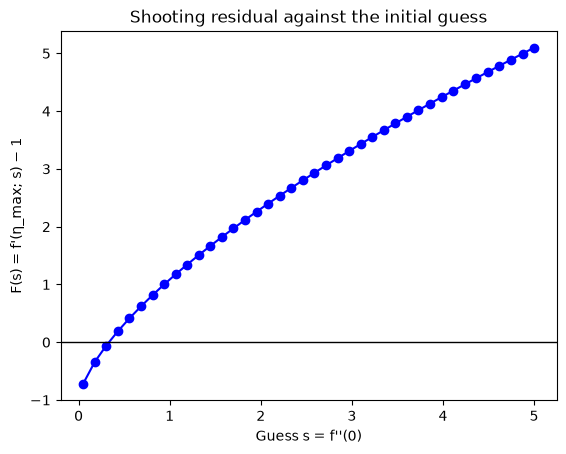

In [4]:
# Diagnostic: shooting residual against the guess s - Claude produced
s_values = np.linspace(0.05, 5.0, 40)
F_values = np.array([F(s) for s in s_values])

plt.plot(s_values, F_values, "o-", color='b')
plt.axhline(0.0, color="black", linewidth=1)
plt.xlabel("Guess s = f''(0)")
plt.ylabel("F(s) = f'(η_max; s) − 1")
plt.title("Shooting residual against the initial guess")
plt.show()